# 04 · Comprobaciones: ¿hay alguna señal de ADNC en la expresión de este subset?

En el notebook 03 los modelos de expresión no superaron al azar en la clasificación de 3 clases. Antes de concluir
que el subset no tiene señal medible, probamos dos problemas más fáciles:

1. **Low frente a High.** Solo los extremos: si la enfermedad deja huella en la expresión, debería verse aquí.
   Métrica principal: **AUC ROC** (0,5 = azar, 1 = perfecto), que no depende de elegir un umbral.
2. **Predecir el CPS.** El *Continuous Pseudo-progression Score* ordena a los donantes de 0 a 1 según su patología
   cuantitativa. **No se puede usar como característica** (sería fuga), pero sí como **objetivo**: al ser continuo
   aprovecha más información que tres clases. Métrica: correlación de Spearman entre predicción y CPS real
   (0 = azar).

En los dos casos comparamos con el **modelo trampa** (solo número de células y recuentos), con las mismas
particiones por donante y todo el preprocesado dentro de cada pliegue.

**Ejecución** (~5–10 min): `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=3600 notebooks\04_comprobaciones.ipynb`

In [1]:
import json
import sys
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.linear_model import LinearRegression, LogisticRegression, LogisticRegressionCV, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tfm import baselines as B
from tfm import evaluation as E
from tfm.config import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

cfg = load_config(ROOT)
COL, PB, EV, BL = cfg["columns"], cfg["pseudobulk"], cfg["evaluation"], cfg["baselines"]
ORDEN, SEED = cfg["labels"]["classification"], cfg["seed"]
TABLAS, FIGS = cfg["paths"]["tables"], cfg["paths"]["figures"]
PALETA = dict(zip(ORDEN, ["#4daf4a", "#ff7f00", "#e41a1c"]))
CPS = "Continuous Pseudo-progression Score"

def guardar(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", encoding="utf-8"); return df

def guardar_fig(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", dpi=150, bbox_inches="tight")

pb = ad.read_h5ad(ROOT / PB["file"])
pb_ig = ad.read_h5ad(ROOT / PB["file_igualado"])
datos, y = B.build_type_data(pb_ig, pb, cfg)

def logistica_expr(n_tech):
    return make_pipeline(B.LogCPMTopVar(BL["n_genes"], PB["min_cpm"], PB["min_frac"], n_tech), StandardScaler(),
                         LogisticRegressionCV(Cs=BL["logistica_Cs"], cv=3, max_iter=5000, class_weight="balanced",
                                              random_state=SEED))

def logistica_tec(n_tech):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced"))

def ridge_expr(n_tech):
    return make_pipeline(B.LogCPMTopVar(BL["n_genes"], PB["min_cpm"], PB["min_frac"], n_tech), StandardScaler(),
                         RidgeCV(alphas=np.logspace(0, 5, 11)))

def lineal_tec(n_tech):
    return make_pipeline(StandardScaler(), LinearRegression())

## 1. Low frente a High

12 donantes Low y 41 High. Validación cruzada por donante: 5 pliegues estratificados × 10 repeticiones.

In [2]:
clases = ["Low", "High"]
datos_lh, y_lh = B.restrict(datos, y, clases)
splits_lh = E.donor_splits(y_lh.values, n_splits=EV["n_splits"], n_repeats=EV["n_repeats_baselines"], seed=SEED)
MOD_LH = {"trampa (técnicas)": (logistica_tec, "tecnicas"), "logística (expresión)": (logistica_expr, "expresion")}
met_lh, prob_lh = B.run_baselines(datos_lh, y_lh, splits_lh, MOD_LH, clases)

filas = []
for (m, t), P in prob_lh.items():
    for rep, auc in enumerate(B.auc_by_rep(P, y_lh, "High", clases)):
        filas.append({"modelo": m, "tipo": t, "repeticion": rep, "auc": auc})
for m in MOD_LH:
    _, P = B.fuse(prob_lh, y_lh, clases, m)
    for rep, auc in enumerate(B.auc_by_rep(P, y_lh, "High", clases)):
        filas.append({"modelo": m, "tipo": "fusión", "repeticion": rep, "auc": auc})
auc_lh = pd.DataFrame(filas)
tabla_lh = auc_lh.groupby(["tipo", "modelo"])["auc"].agg(["mean", "std"]).unstack("modelo")
guardar(tabla_lh, "comprobacion_low_high_auc")
print(f"Donantes: {y_lh.value_counts().to_dict()}  |  AUC ROC (media y sd en 10 repeticiones; azar = 0,5)")
display(tabla_lh.round(3))

  AST        trampa (técnicas)                 0 s


  AST        logística (expresión)             8 s


  L2IT-GLU   trampa (técnicas)                 8 s


  L2IT-GLU   logística (expresión)            16 s
  MGC        trampa (técnicas)                16 s


  MGC        logística (expresión)            24 s
  OLG        trampa (técnicas)                24 s


  OLG        logística (expresión)            31 s
  SST-GABA   trampa (técnicas)                31 s


  SST-GABA   logística (expresión)            38 s
  VIP-GABA   trampa (técnicas)                38 s


  VIP-GABA   logística (expresión)            46 s


Donantes: {'High': 41, 'Low': 12}  |  AUC ROC (media y sd en 10 repeticiones; azar = 0,5)


mean                                     std                  
modelo   logística (expresión) trampa (técnicas) logística (expresión) trampa (técnicas)
tipo                                                                                    
AST                      0.704             0.867                 0.057             0.009
L2IT-GLU                 0.598             0.977                 0.048             0.003
MGC                      0.593             0.870                 0.064             0.008
OLG                      0.468             0.897                 0.053             0.008
SST-GABA                 0.636             0.895                 0.046             0.006
VIP-GABA                 0.727             0.928                 0.041             0.006
fusión                   0.702             0.986                 0.033             0.001

## 2. Predecir el CPS

Objetivo continuo para los 74 donantes. Modelos: regresión ridge sobre la expresión (la regularización se elige
por validación interna) y, como trampa, regresión lineal sobre las variables técnicas. Las particiones se
estratifican por clase de ADNC para que cada pliegue tenga donantes de todo el rango.

In [3]:
cps = pb.obs.groupby(pb.obs[COL["donor"]].astype(str), observed=True)[CPS].first().astype(float).reindex(y.index)
print(f"CPS disponible en {cps.notna().sum()} de {len(cps)} donantes")
print(cps.groupby(y).describe()[["count", "mean", "min", "max"]].reindex(ORDEN).round(3))

n_cel = pb.obs.groupby(pb.obs[COL["donor"]].astype(str), observed=True)["n_celulas"].sum().reindex(y.index)
rho, p = stats.spearmanr(cps, np.log10(n_cel))
print(f"\nSpearman CPS vs log(n_celulas del donante): {rho:.3f} (p = {p:.2g})")

ok = cps.notna()
datos_c = {t: (c.loc[c.index.isin(cps.index[ok])], tec.loc[tec.index.isin(cps.index[ok])]) for t, (c, tec) in datos.items()}
cps_ok, y_ok = cps[ok], y[ok]
splits_c = E.donor_splits(y_ok.values, n_splits=EV["n_splits"], n_repeats=EV["n_repeats_baselines"], seed=SEED)
MOD_C = {"trampa (técnicas)": (lineal_tec, "tecnicas"), "ridge (expresión)": (ridge_expr, "expresion")}
met_c, pred_c = B.run_regression(datos_c, cps_ok, splits_c, MOD_C)
fus_c = {m: B.fuse_regression(pred_c, cps_ok, m) for m in MOD_C}
todo_c = pd.concat([met_c] + [f[0] for f in fus_c.values()])
tabla_c = guardar(B.summarize_by(todo_c, metricas=("spearman", "r2")), "comprobacion_cps_regresion")
display(tabla_c.round(3))

CPS disponible en 74 de 74 donantes
              count   mean    min    max
ADNC                                    
Low            12.0  0.350  0.150  0.644
Intermediate   21.0  0.602  0.225  0.879
High           41.0  0.784  0.371  0.929

Spearman CPS vs log(n_celulas del donante): -0.616 (p = 5e-09)
  AST        trampa (técnicas)                 0 s


  AST        ridge (expresión)                 6 s
  L2IT-GLU   trampa (técnicas)                 6 s


  L2IT-GLU   ridge (expresión)                13 s
  MGC        trampa (técnicas)                13 s


  MGC        ridge (expresión)                20 s
  OLG        trampa (técnicas)                20 s


  OLG        ridge (expresión)                26 s
  SST-GABA   trampa (técnicas)                27 s


  SST-GABA   ridge (expresión)                33 s
  VIP-GABA   trampa (técnicas)                33 s


  VIP-GABA   ridge (expresión)                40 s


spearman_media  spearman_sd  r2_media  r2_sd  n_donantes
tipo     modelo                                                                     
AST      ridge (expresión)           0.559        0.026     0.274  0.015          64
         trampa (técnicas)           0.099        0.047    -0.024  0.034          64
L2IT-GLU ridge (expresión)           0.443        0.044     0.162  0.051          63
         trampa (técnicas)           0.355        0.023     0.093  0.018          63
MGC      ridge (expresión)           0.508        0.029     0.222  0.027          63
         trampa (técnicas)           0.297        0.040     0.069  0.033          63
OLG      ridge (expresión)           0.480        0.048     0.142  0.033          60
         trampa (técnicas)           0.451        0.021     0.189  0.027          60
SST-GABA ridge (expresión)           0.447        0.033     0.164  0.029          63
         trampa (técnicas)           0.400        0.023     0.166  0.029          63
VIP-GABA ridge (expresión)           0.474        0.051     0.202  0.037          66
         trampa (técnicas)           0.399        0.019     0.128  0.020          66
fusión   ridge (expresión)           0.579        0.029     0.248  0.025          74
         trampa (técnicas)           0.478        0.029     0.203  0.014          74

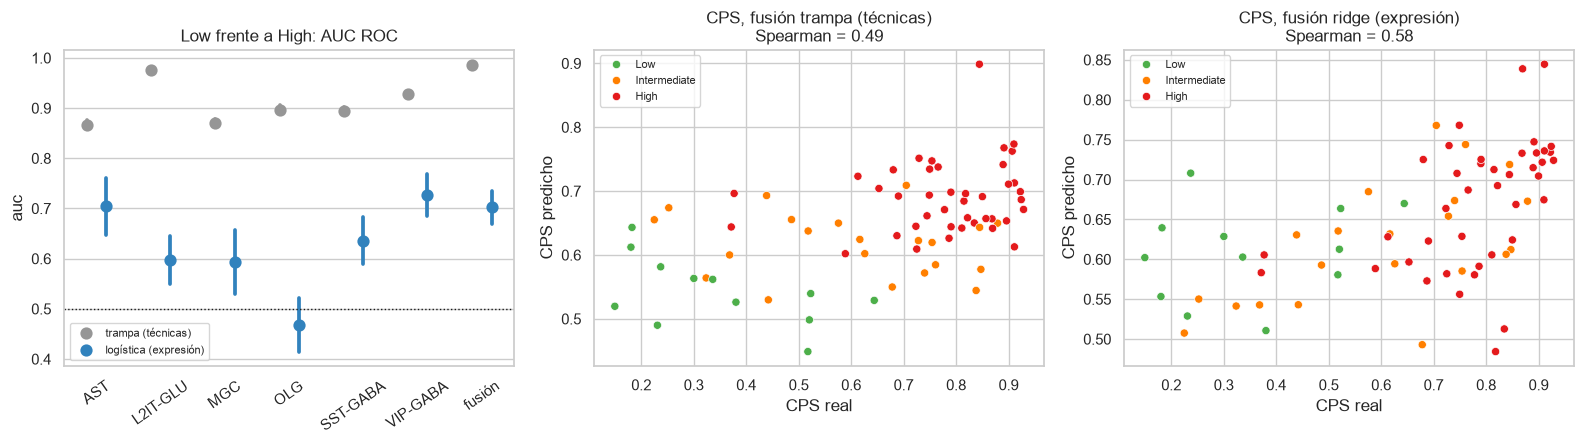

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
sns.pointplot(data=auc_lh, x="tipo", y="auc", hue="modelo", order=sorted(datos) + ["fusión"], dodge=0.3,
              errorbar="sd", linestyle="none", palette=["#969696", "#3182bd"], ax=axs[0])
axs[0].axhline(0.5, color="k", ls=":", lw=1); axs[0].set_title("Low frente a High: AUC ROC")
axs[0].set_xlabel(""); axs[0].tick_params(axis="x", rotation=35); axs[0].legend(fontsize=8)
for ax, m in zip(axs[1:], MOD_C):
    Y = fus_c[m][1].mean(0)
    sns.scatterplot(x=cps_ok.values, y=Y, hue=y_ok.values, hue_order=ORDEN, palette=PALETA, ax=ax, s=35)
    r = stats.spearmanr(cps_ok, Y)[0]
    ax.set_title(f"CPS, fusión {m}\nSpearman = {r:.2f}"); ax.set_xlabel("CPS real"); ax.set_ylabel("CPS predicho")
    ax.legend(fontsize=8)
fig.tight_layout(); guardar_fig(fig, "comprobaciones"); plt.show()

## 3. ¿Qué valores salen sin señal? Prueba de permutación

Con pocos donantes, la validación cruzada no da exactamente el valor de azar teórico cuando no hay señal:
la correlación con el CPS tiende a salir **negativa** (al apartar donantes de un extremo, la media del
entrenamiento se desplaza hacia el otro) y el AUC puede quedar algo por debajo de 0,5.

Para saber qué es "azar" de verdad, **barajamos la etiqueta entre donantes** (rompiendo cualquier relación con la
expresión), repetimos todo el proceso y guardamos el resultado de la fusión de expresión. Si el valor real cae
dentro de la distribución barajada, no hay señal detectable.

In [5]:
N_PERM = 20
rng = np.random.default_rng(SEED)
nulo = {"auc_low_high": [], "spearman_cps": []}
for i in range(N_PERM):
    yp = pd.Series(rng.permutation(y_lh.values), index=y_lh.index)
    sp_ = E.donor_splits(yp.values, n_splits=EV["n_splits"], n_repeats=1, seed=SEED + i)
    _, pr = B.run_baselines(datos_lh, yp, sp_, {"logística (expresión)": MOD_LH["logística (expresión)"]}, clases, verbose=False)
    nulo["auc_low_high"].append(B.auc_by_rep(B.fuse(pr, yp, clases, "logística (expresión)")[1], yp, "High", clases)[0])

    cp = pd.Series(rng.permutation(cps_ok.values), index=cps_ok.index)
    sp_ = E.donor_splits(y_ok.values, n_splits=EV["n_splits"], n_repeats=1, seed=SEED + i)
    _, pc = B.run_regression(datos_c, cp, sp_, {"ridge (expresión)": MOD_C["ridge (expresión)"]}, verbose=False)
    nulo["spearman_cps"].append(B.fuse_regression(pc, cp, "ridge (expresión)")[0]["spearman"].iloc[0])
    print(f"\\r  permutación {i + 1}/{N_PERM}", end="")
print()

obs = {"auc_low_high": auc_lh[(auc_lh.tipo == "fusión") & (auc_lh.modelo == "logística (expresión)")]["auc"].mean(),
       "spearman_cps": todo_c[(todo_c.tipo == "fusión") & (todo_c.modelo == "ridge (expresión)")]["spearman"].mean()}
perm = pd.DataFrame({k: {"observado": obs[k], "nulo_media": np.mean(v), "nulo_p5": np.percentile(v, 5),
                         "nulo_p95": np.percentile(v, 95),
                         "p_empirico": (1 + np.sum(np.array(v) >= obs[k])) / (1 + len(v))} for k, v in nulo.items()}).T
guardar(perm, "comprobaciones_permutacion")
display(perm.round(3))

\r  permutación 1/20

\r  permutación 2/20

\r  permutación 3/20

\r  permutación 4/20

\r  permutación 5/20

\r  permutación 6/20

... (11 outputs left out)

\r  permutación 18/20

\r  permutación 19/20

\r  permutación 20/20


,observado,nulo_media,nulo_p5,nulo_p95,p_empirico
auc_low_high,0.702,0.500,0.349,0.633,0.048
spearman_cps,0.579,-0.084,-0.345,0.130,0.048


In [6]:
resumen = {
    "low_vs_high_auc": {f"{t} | {m}": round(float(v), 3) for (t, m), v in auc_lh.groupby(["tipo", "modelo"])["auc"].mean().items()},
    "cps_spearman": {f"{t} | {m}": round(float(v), 3) for (t, m), v in todo_c.groupby(["tipo", "modelo"])["spearman"].mean().items()},
    "cps_r2": {f"{t} | {m}": round(float(v), 3) for (t, m), v in todo_c.groupby(["tipo", "modelo"])["r2"].mean().items()},
    "spearman_cps_vs_log_n_celulas": round(float(rho), 3),
    "permutacion": perm.round(3).to_dict(orient="index"),
}
(TABLAS / "comprobaciones_resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "low_vs_high_auc": {
    "AST | logística (expresión)": 0.704,
    "AST | trampa (técnicas)": 0.867,
    "L2IT-GLU | logística (expresión)": 0.598,
    "L2IT-GLU | trampa (técnicas)": 0.977,
    "MGC | logística (expresión)": 0.593,
    "MGC | trampa (técnicas)": 0.87,
    "OLG | logística (expresión)": 0.468,
    "OLG | trampa (técnicas)": 0.897,
    "SST-GABA | logística (expresión)": 0.636,
    "SST-GABA | trampa (técnicas)": 0.895,
    "VIP-GABA | logística (expresión)": 0.727,
    "VIP-GABA | trampa (técnicas)": 0.928,
    "fusión | logística (expresión)": 0.702,
    "fusión | trampa (técnicas)": 0.986
  },
  "cps_spearman": {
    "AST | ridge (expresión)": 0.559,
    "AST | trampa (técnicas)": 0.099,
    "L2IT-GLU | ridge (expresión)": 0.443,
    "L2IT-GLU | trampa (técnicas)": 0.355,
    "MGC | ridge (expresión)": 0.508,
    "MGC | trampa (técnicas)": 0.297,
    "OLG | ridge (expresión)": 0.48,
    "OLG | trampa (técnicas)": 0.451,
    "SST-GABA | ridge (expresión)": 0.447,
